# REPD — Applications and capacity per year, by technology

Two stacked bar charts on a shared year axis, saved as separate images: how many planning applications were submitted each year, and how much capacity (GW) they applied for, both split by technology.

**Year** is the year of `Planning Application Submitted`. The current year is partial and is marked with an asterisk.
**Capacity** is `Installed Capacity (MWelec)` shown in GW; rows without a capacity count in the top chart but add nothing to the bottom one.
Each chart shows its own top `TOP_N` technologies (so the two may differ), with everything else folded into **Other**. A technology keeps the same colour on both charts.


In [1]:
from pathlib import Path

import matplotlib.colors as mcolors
import pandas as pd

from repd.processor import REPDProcessor
from repd.visualise import plot_stacked_bars

REPD_CSV = Path("../data/REPD_Publication_Q2_2026.csv")
YEARS = (2000, None)  # None = up to the latest year in the data
TOP_N = 6  # technologies shown per chart; the rest become "Other"

## 1. Load and aggregate

In [2]:
processor = REPDProcessor(REPD_CSV, encoding="latin-1")
df = processor.convert_datetime(processor.load())

df = df.dropna(subset=["Planning Application Submitted"]).assign(
    year=lambda d: d["Planning Application Submitted"].dt.year,
    mw=lambda d: pd.to_numeric(d["Installed Capacity (MWelec)"], errors="coerce").fillna(0),
)
last_year = YEARS[1] or df["year"].max()
df = df[df["year"].between(YEARS[0], last_year)]

def top_n(pivot):
    """Keep the TOP_N biggest columns (biggest first = bottom of stack); sum the rest into Other."""
    keep = pivot.sum().sort_values(ascending=False).index[:TOP_N]
    return pivot[keep].assign(Other=pivot.drop(columns=keep).sum(axis=1))

counts = top_n(df.pivot_table(index="year", columns="Technology Type", values="Ref ID", aggfunc="size", fill_value=0))
capacity = top_n(df.pivot_table(index="year", columns="Technology Type", values="mw", aggfunc="sum", fill_value=0)) / 1000  # GW

# One colour per technology, shared by both charts.
techs = sorted(set(counts.columns) | set(capacity.columns) - {"Other"})
colors = {t: mcolors.hsv_to_rgb((i / len(techs), 0.85, 0.92)) for i, t in enumerate(techs)} | {"Other": "#6b6158"}

# Mark the partial current year.
latest = df["Record Last Updated (dd/mm/yyyy)"].max()
label = lambda y: f"{y}*" if y == latest.year else str(y)
counts.index = capacity.index = [label(y) for y in counts.index]

print(f"{len(df):,} applications, {YEARS[0]}–{last_year}; MW missing on {(df['mw'] == 0).sum():,} rows")
pd.DataFrame({"applications": counts.sum(axis=1), "GW": capacity.sum(axis=1).round(1)}).tail(8)

14,074 applications, 2000–2026; MW missing on 1,317 rows


,applications,GW
2019,328,9.9
2020,396,7.8
2021,849,22.1
2022,1454,34.7
2023,1864,46.5
2024,1738,67.6
2025,1861,70.0
2026*,585,17.7


## 2. Chart

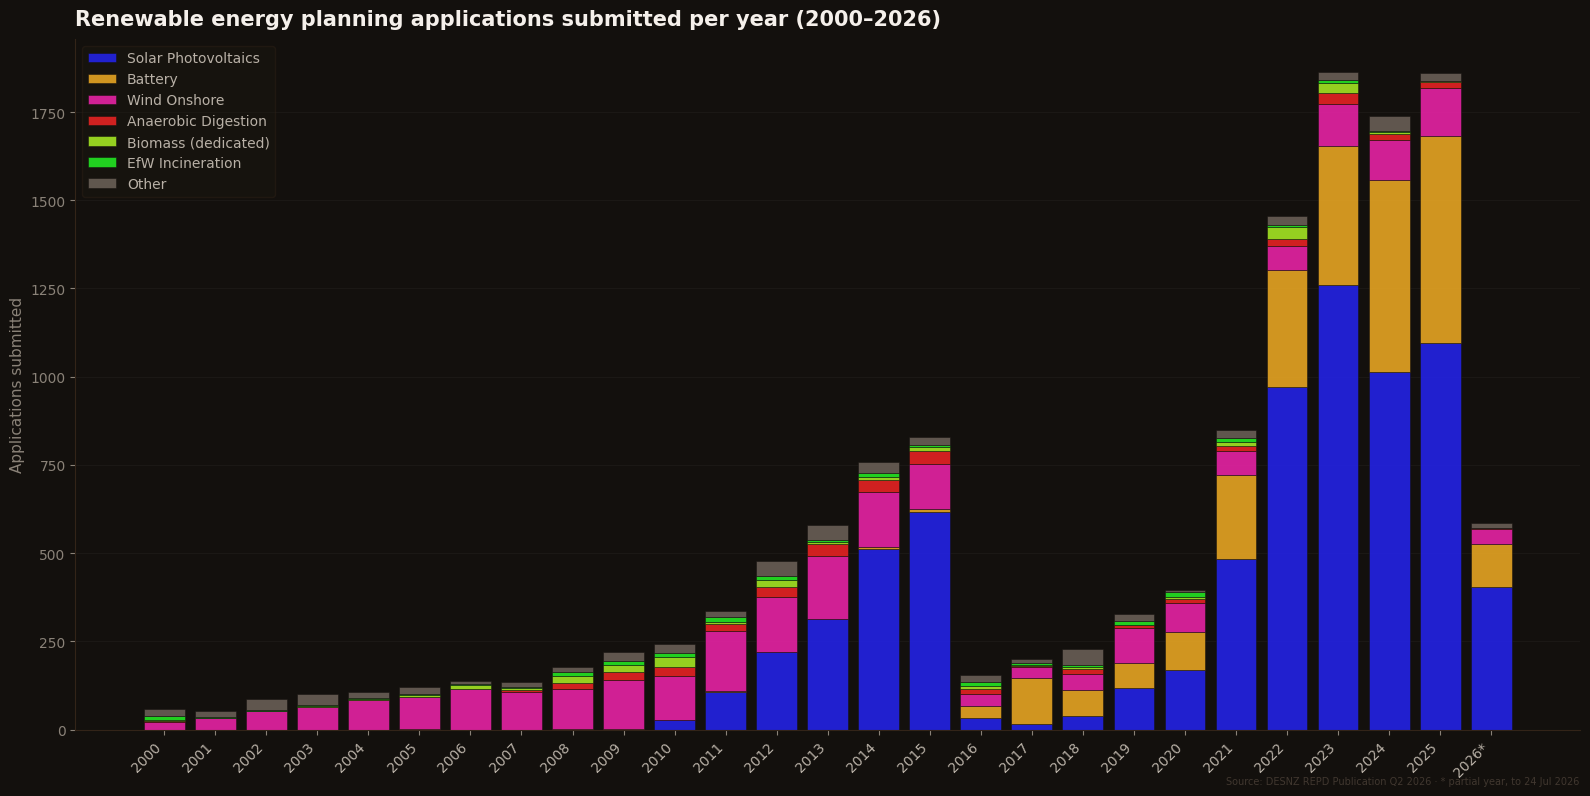

In [3]:
credit = f"Source: DESNZ {REPD_CSV.stem.replace('_', ' ')} · * partial year, to {latest:%d %b %Y}"

fig = plot_stacked_bars(
    counts,
    f"Renewable energy planning applications submitted per year ({YEARS[0]}–{last_year})",
    "Applications submitted",
    credit=credit,
    colors=colors,
)
fig.savefig("barchart_applications.png", dpi=150, bbox_inches="tight")


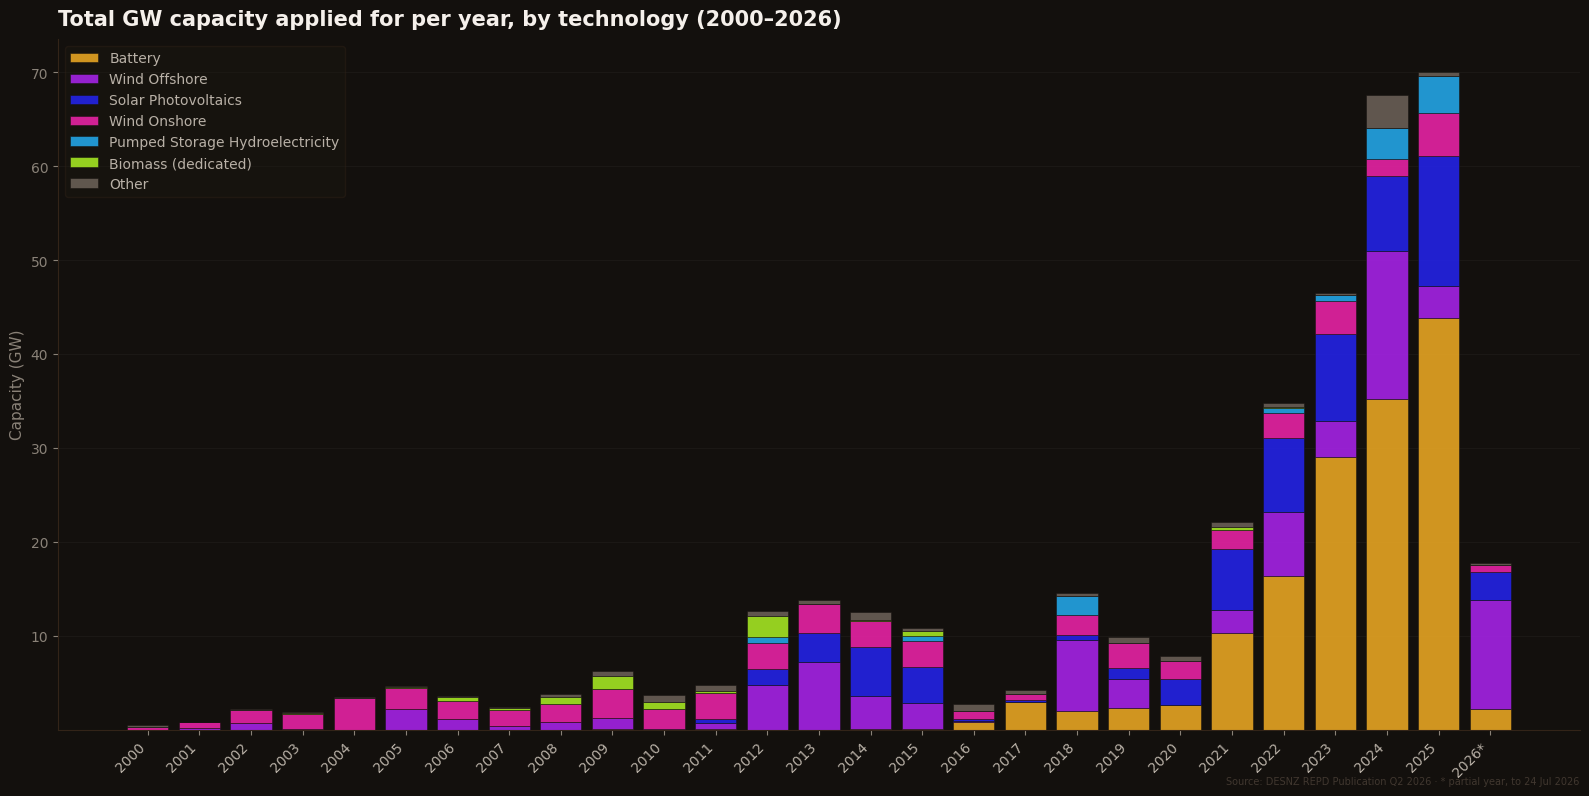

In [4]:
fig = plot_stacked_bars(
    capacity,
    f"Total GW capacity applied for per year, by technology ({YEARS[0]}–{last_year})",
    "Capacity (GW)",
    credit=credit,
    colors=colors,
)
fig.savefig("barchart_capacity.png", dpi=150, bbox_inches="tight")


## 3. Top technologies, latest full year

In [5]:
full = counts.index[-2] if counts.index[-1].endswith("*") else counts.index[-1]
pd.DataFrame({"applications": counts.loc[full], "GW": capacity.loc[full].round(1)}).sort_values("applications", ascending=False).head(8)

,applications,GW
Technology Type,,
Solar Photovoltaics,1096.0,13.9
Battery,585.0,43.9
Wind Onshore,137.0,4.6
Other,23.0,0.5
Anaerobic Digestion,16.0,NaN
Biomass (dedicated),4.0,0.0
EfW Incineration,0.0,NaN
Pumped Storage Hydroelectricity,NaN,3.9
